# Checkpoint 1 · Notebook 01: Target Screening & Dataset Check

**Project 7 — Repurposing Approved Drugs Against One Target**

- **Selected Target:** **AChE** (Acetylcholinesterase)
- **Target IDs:** ChEMBL `CHEMBL220` · UniProt `P22303` · Ensembl `ENSG00000087085`
- **Research Question (one sentence):** *For human **AChE** (`CHEMBL220`), which approved small-molecule drugs do ligand-based QSAR models rank as candidate binders—and does the leak-free ranking recover the drugs already approved against AChE?*

> **Reproducibility:** Managed with `uv` (`pyproject.toml` + `uv.lock`). All curation and splitting functions reuse our verified Assignment 5 (CAP5) implementations in `src/bioinfo_repurposing/`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bioinfo_repurposing.curation import (
    curate_activity,
    curate_activity_classification,
    filter_approved_small_molecules,
    remove_leakage,
    replicate_disagreement_report,
)
from bioinfo_repurposing.features import ecfp4_bitvects, murcko_scaffold

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path("..").resolve()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "AChE"
TARGET_LOW = TARGET.lower()


## 1. Multi-Target Screening (All Slide 13 Targets + CDK2 & CDK9)

Before committing to one target, we queried **ChEMBL** (live REST API), **Open Targets Platform** (GraphQL `drugAndClinicalCandidates`), and **RCSB PDB** across all Slide 13 targets plus our group's initial candidates (**CDK2** and **CDK9**).

Key verification result:
- **CDK2 (`CHEMBL301`) and CDK9 (`CHEMBL3116`) have 0 FDA-approved (Phase 4 / APPROVAL) drugs** with primary approved mechanism of action in both ChEMBL and Open Targets (all CDK2/CDK9 agents such as dinaciclib, alvocidib, and seliciclib are Phase I–III investigational; approved CDK drugs target CDK4/6).
- Because Project 7's central validation test requires recovering drugs *already approved against the target*, we select the Slide 13 target offering the strongest balance of **rich curated IC50 bioactivity data**, **many approved positive controls**, and **abundant PDB co-crystal structures**.


In [2]:
screen_df = pd.read_csv(PROC_DIR / "target_screening_summary.csv")
display(
    screen_df[
        [
            "symbol",
            "source_list",
            "chembl_id",
            "chembl_ic50_records",
            "chembl_ki_records",
            "chembl_mech_phase4_sm",
            "opentargets_phase4_sm",
            "approved_pos_controls_union",
            "pdb_holo_structures",
            "top_pdb_ids",
        ]
    ]
)

cdk_check = screen_df[screen_df["symbol"].isin(["CDK2", "CDK9"])]
print("\n--- Explicit Verification: CDK2 & CDK9 Approved Drug Counts ---")
display(cdk_check[["symbol", "chembl_id", "ensembl", "chembl_mech_phase4_sm", "opentargets_phase4_sm", "approved_pos_controls_union"]])


,symbol,source_list,chembl_id,chembl_ic50_records,chembl_ki_records,chembl_mech_phase4_sm,opentargets_phase4_sm,approved_pos_controls_union,pdb_holo_structures,top_pdb_ids
0,DRD2,Slide 13,CHEMBL217,2480,14842,42,57,63,12,"5AER, 9BS9, 9BSB"
1,SLC6A4,Slide 13,CHEMBL228,5130,4678,25,25,28,31,"9HCO, 7TXT, 5I6X"
2,AChE,Slide 13,CHEMBL220,10079,1970,16,18,21,76,"4M0E, 6NTO, 5HF5"
3,ABL1,Slide 13,CHEMBL1862,5295,1781,7,8,8,71,"5OAZ, 7PVS, 4J9C"
4,BRAF,Slide 13,CHEMBL5145,11017,47,5,6,6,127,"8VSO, 8JNB, 8C7X"
5,PARP1,Slide 13,CHEMBL3105,4993,1212,2,6,6,102,"6NRH, 9ETQ, 7AAC"
6,NTRK1,Slide 13,CHEMBL2815,10647,934,2,5,5,56,"5JFW, 5JFV, 5JFX"
7,ADORA2A,Slide 13,CHEMBL251,3050,9055,2,5,5,190,"5NM4, 9H37, 5IU4"
8,NTRK2,Slide 13,CHEMBL4898,924,957,1,4,4,6,"4AT5, 4AT3, 30PP"
9,NTRK3,Slide 13,CHEMBL5608,556,704,1,4,4,4,"6KZD, 4YMJ, 6KZC"



--- Explicit Verification: CDK2 & CDK9 Approved Drug Counts ---


,symbol,chembl_id,ensembl,chembl_mech_phase4_sm,opentargets_phase4_sm,approved_pos_controls_union
11,CDK2,CHEMBL301,ENSG00000123374,0,0,0
12,CDK9,CHEMBL3116,ENSG00000136807,0,0,0


## 2. Raw Bioactivity Curation & Dataset Check for `AChE`

We apply Assignment 5 Task A's strict curation rules (`curate_activity`) for **exact-value `pIC50` regression** and extend them (`curate_activity_classification`) for **binary classification**:
1. Remove flagged dubious records (`data_validity_comment` not null) and restrict to biochemical/binding assays (`assay_type == 'B'`) and `IC50` only (avoiding unvalidated mixing of `IC50` and `Ki`).
2. Convert valid molar units (`nM`, `uM`, `M`) to `nM` and drop non-positive values.
3. Standardize molecules with RDKit (`largest_fragment_smiles` + charge neutralization) and compute the 14-character **InChIKey connectivity layer** (`inchikey14`) for leak-proof cross-database matching.
4. Aggregate replicate measurements by **median** `pIC50` and flag compounds with replicate range `> 2.0` log units (Assignment 5 Q1b bookkeeping/unit-error diagnostic).
5. For **classification**: active `pIC50 >= 6.0` (IC50 <= 1 uM), inactive `pIC50 <= 5.0` (IC50 >= 10 uM), dropping the `5–6` grey zone and **rescuing unambiguous censored inactives** (`standard_relation` in `{'>', '>='}` with `IC50 >= 10,000 nM`).


In [3]:
raw_act = pd.read_csv(RAW_DIR / f"{TARGET_LOW}_chembl_activities_raw.csv", low_memory=False)
with open(RAW_DIR / f"{TARGET_LOW}_metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

print(f"ChEMBL version: {meta['chembl_db_version']} | Raw IC50/Ki records: {len(raw_act):,}")
display(
    pd.concat(
        {col: raw_act[col].value_counts(dropna=False).head(6) for col in ["standard_type", "standard_relation", "standard_units", "assay_type"]},
        names=["field", "value"],
    ).to_frame("records")
)

df_reg, reg_funnel = curate_activity(raw_act, standard_type="IC50", return_funnel=True)
df_clf, clf_funnel = curate_activity_classification(
    raw_act, active_threshold=6.0, inactive_threshold=5.0, rescue_censored_inactives=True, standard_type="IC50"
)

funnel_df = pd.DataFrame(
    list(clf_funnel.items()), columns=["curation_step", "count"]
)
display(funnel_df)

disagree = replicate_disagreement_report(raw_act, threshold=2.0)
print(f"\nExact IC50 compounds measured >1 time: {(df_reg['n_measurements'] > 1).sum():,}")
print(f"Compounds whose replicates disagree by > 2.0 log units: {len(disagree):,}")
if len(disagree):
    display(disagree[["pIC50", "n_measurements", "pIC50_min", "pIC50_max", "pIC50_range"]].head(8).round(2))


ChEMBL version: ChEMBL_37 | Raw IC50/Ki records: 9,882


records
field             value               
standard_type     IC50            9882
standard_relation =               7720
                  nan             1281
                  >                864
                  <                 13
                  ~                  2
                  >>                 2
standard_units    nM              8531
                  nan             1260
                  ug.mL-1           83
                  10'5pM             3
                  10'6pM             2
                  10^-4microM        2
assay_type        B               9882

,curation_step,count
0,raw_records,9882
1,after_data_validity_check,9253
2,after_binding_assay_B,9253
3,after_type_IC50,9253
4,after_relation_filter,7260
5,after_molar_units,7193
6,after_positive_values,7193
7,after_valid_smiles_standardization,7192
8,unique_curated_compounds,5664
9,exact_actives,2799



Exact IC50 compounds measured >1 time: 570
Compounds whose replicates disagree by > 2.0 log units: 47


,pIC50,n_measurements,pIC50_min,pIC50_max,pIC50_range
canonical_smiles,,,,,
CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,7.19,16,4.16,10.37,6.21
O=C(CCc1c[nH]c2ccccc12)NCCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,10.22,3,5.05,10.70,5.65
CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCNc4c5c(nc6ccccc46)CCCC5)c3C(C1)C2,8.86,3,4.21,9.48,5.27
O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,9.60,8,4.35,9.60,5.26
O=C(CCc1c[nH]c2ccccc12)NCCCCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,10.15,3,5.70,10.70,5.00
CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,7.40,53,4.60,9.37,4.76
CCN(CCCCCCNC1=CC(=O)C(NCCCCCCN(CC)[C@@H](C)c2ccccc2OC)=CC1=O)[C@H](C)c1ccccc1OC,7.20,2,4.96,9.44,4.49
CCN(CCCCCCN1C(=O)c2ccc3c4c(ccc(c24)C1=O)C(=O)N(CCCCCCN(CC)Cc1ccccc1OC)C3=O)Cc1ccccc1OC,7.26,2,5.09,9.43,4.34


## 3. Approved Small-Molecule Library & Positive-Control Matching (Leakage Check)

We curate the **100% open-access ChEMBL `max_phase == 4` small-molecule library** identically (salt stripping, neutralization, organic elements only, `100 <= MW <= 900 Da`, `heavy_atoms >= 6`, deduplicated by `inchikey14`).

Then we cross-match our positive controls (union of ChEMBL `mechanism` Phase 4 and Open Targets `APPROVAL / PHASE_4`) onto the curated approved library and measure **exact overlap** and **close-analogue overlap (`Tanimoto >= 0.85`)** with the ChEMBL training data.


In [4]:
raw_drugs = pd.read_csv(RAW_DIR / "chembl_approved_small_molecules_raw.csv", low_memory=False)
raw_pos = pd.read_csv(RAW_DIR / f"{TARGET_LOW}_positive_controls_raw.csv")

approved_df, drug_funnel = filter_approved_small_molecules(raw_drugs)
display(pd.DataFrame(list(drug_funnel.items()), columns=["approved_library_step", "count"]))

# Match positive controls via both molecule_chembl_id and standardized InChIKey14
pos_ids = set(raw_pos["molecule_chembl_id"].dropna())
pos_raw_rows = raw_drugs[raw_drugs["molecule_chembl_id"].isin(pos_ids)].copy()
pos_std, _ = filter_approved_small_molecules(pos_raw_rows)
pos_iks = set(pos_std["inchikey14"].dropna())

approved_df["is_positive_control"] = (
    approved_df["molecule_chembl_id"].isin(pos_ids) | approved_df["inchikey14"].isin(pos_iks)
).astype(int)

print(f"Curated approved small-molecule library: {len(approved_df):,} unique drugs")
print(f"Positive controls matched in curated library: {approved_df['is_positive_control'].sum()} / {len(raw_pos)}")
display(approved_df[approved_df["is_positive_control"] == 1][["molecule_chembl_id", "pref_name", "first_approval", "MolWt", "inchikey14"]].head(25))

# Compute ECFP4 fingerprints for leakage audit
reg_fps = ecfp4_bitvects(df_reg.index)
clf_fps = ecfp4_bitvects(df_clf.index)
app_fps = ecfp4_bitvects(approved_df["canonical_smiles"])

df_reg_exact_clean, reg_leak_exact = remove_leakage(df_reg, approved_df, reg_fps, app_fps, tanimoto_cutoff=None)
df_reg_strict_clean, reg_leak_strict = remove_leakage(df_reg, approved_df, reg_fps, app_fps, tanimoto_cutoff=0.85)

df_clf_exact_clean, clf_leak_exact = remove_leakage(df_clf, approved_df, clf_fps, app_fps, tanimoto_cutoff=None)
df_clf_strict_clean, clf_leak_strict = remove_leakage(df_clf, approved_df, clf_fps, app_fps, tanimoto_cutoff=0.85)

# Check how many positive controls themselves appear in ChEMBL training!
pos_only_df = approved_df[approved_df["is_positive_control"] == 1]
pos_in_reg = int(df_reg["inchikey14"].isin(set(pos_only_df["inchikey14"])).sum())
pos_in_clf = int(df_clf["inchikey14"].isin(set(pos_only_df["inchikey14"])).sum())
print(f"\nPositive controls present in raw ChEMBL regression set: {pos_in_reg} / {len(pos_only_df)}")
print(f"Positive controls present in raw ChEMBL classification set: {pos_in_clf} / {len(pos_only_df)}")

leak_summary = pd.DataFrame(
    [
        {"dataset": "Regression (exact IC50)", "tier": "Exact leak-free", **reg_leak_exact},
        {"dataset": "Regression (exact IC50)", "tier": "Strict (Tanimoto<0.85)", **reg_leak_strict},
        {"dataset": "Classification (<=5 vs >=6 + censored)", "tier": "Exact leak-free", **clf_leak_exact},
        {"dataset": "Classification (<=5 vs >=6 + censored)", "tier": "Strict (Tanimoto<0.85)", **clf_leak_strict},
    ]
)
display(leak_summary)


,approved_library_step,count
0,raw_approved_records,3475
1,after_valid_smiles,3311
2,after_organic_filter,3234
3,after_mw_and_size_filter,3138
4,unique_approved_small_molecules,2027


Curated approved small-molecule library: 2,027 unique drugs
Positive controls matched in curated library: 18 / 21


,molecule_chembl_id,pref_name,first_approval,MolWt,inchikey14
160,CHEMBL94,PHYSOSTIGMINE,NaN,275.352,PIJVFDBKTWXHHD
161,CHEMBL95,TACRINE,1993.0,198.269,YLJREFDVOIBQDA
162,CHEMBL502,DONEPEZIL,1996.0,379.500,ADEBPBSSDYVVLD
204,CHEMBL278020,NEOSTIGMINE,2013.0,223.296,ALWKGYPQUAPLQC
317,CHEMBL636,RIVASTIGMINE,1998.0,250.342,XSVMFMHYUFZWBK
344,CHEMBL659,GALANTAMINE,2001.0,287.359,ASUTZQLVASHGKV
386,CHEMBL278819,MINAPRINE,NaN,298.390,LDMWSLGGVTVJPG
419,CHEMBL748,PRALIDOXIME CHLORIDE,1964.0,137.162,JBKPUQTUERUYQE
468,CHEMBL812,PYRIDOSTIGMINE BROMIDE,1955.0,181.215,RVOLLAQWKVFTGE
669,CHEMBL1025,ISOFLUROPHATE,1957.0,184.147,MUCZHBLJLSDCSD



Positive controls present in raw ChEMBL regression set: 14 / 18
Positive controls present in raw ChEMBL classification set: 7 / 18


,dataset,tier,n_before,n_exact_overlap,n_analogue_overlap,n_removed_total,n_after
0,Regression (exact IC50),Exact leak-free,5664,51,0,51,5613
1,Regression (exact IC50),Strict (Tanimoto<0.85),5664,51,3,54,5610
2,Classification (<=5 vs >=6 + censored),Exact leak-free,4366,28,0,28,4338
3,Classification (<=5 vs >=6 + censored),Strict (Tanimoto<0.85),4366,28,1,29,4337


## 4. Chemical Diversity (Bemis–Murcko Scaffolds), Plots & Saving Processed Datasets

We inspect the `pIC50` distribution, class balance, and Bemis–Murcko scaffold diversity (Assignment 5 Part 2), then save all versioned datasets to `data/processed/` for Notebook 02.


Leak-free classification set: 4,338 compounds · 2,095 distinct Bemis-Murcko scaffolds · largest series: 88 · singletons: 1,492


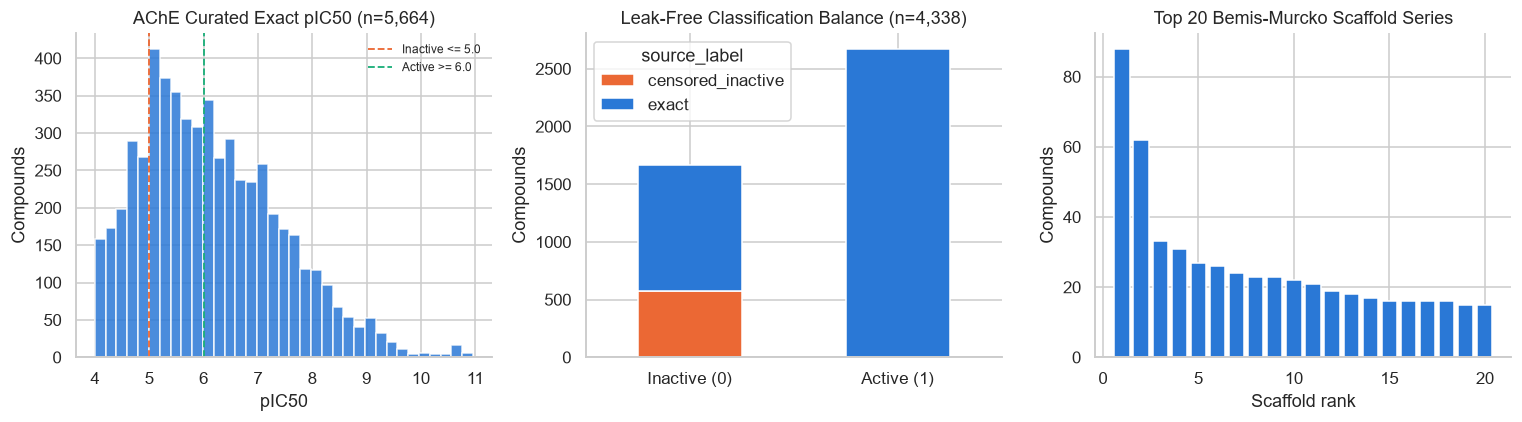

Saved all processed datasets and figures successfully.


In [5]:
scaffs_clf = pd.Series([murcko_scaffold(s) for s in df_clf_exact_clean.index], index=df_clf_exact_clean.index)
scaff_sizes = scaffs_clf.value_counts()
print(
    f"Leak-free classification set: {len(df_clf_exact_clean):,} compounds · "
    f"{scaffs_clf.nunique():,} distinct Bemis-Murcko scaffolds · "
    f"largest series: {scaff_sizes.iloc[0]} · singletons: {(scaff_sizes == 1).sum():,}"
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df_reg["pIC50"], bins=35, color="#2a78d6", alpha=0.85)
axes[0].axvline(5.0, color="#eb6834", ls="--", lw=1.2, label="Inactive <= 5.0")
axes[0].axvline(6.0, color="#1baf7a", ls="--", lw=1.2, label="Active >= 6.0")
axes[0].set(title=f"{TARGET} Curated Exact pIC50 (n={len(df_reg):,})", xlabel="pIC50", ylabel="Compounds")
axes[0].legend(frameon=False, fontsize=8)

cls_counts = df_clf_exact_clean.groupby(["y", "source_label"]).size().unstack(fill_value=0)
cls_counts.index = ["Inactive (0)", "Active (1)"]
cls_counts.plot(kind="bar", stacked=True, ax=axes[1], color=["#eb6834", "#2a78d6"])
axes[1].set(title=f"Leak-Free Classification Balance (n={len(df_clf_exact_clean):,})", ylabel="Compounds")
axes[1].tick_params(axis="x", rotation=0)

axes[2].bar(range(1, min(21, len(scaff_sizes) + 1)), scaff_sizes.iloc[:20].to_numpy(), color="#2a78d6")
axes[2].set(title="Top 20 Bemis-Murcko Scaffold Series", xlabel="Scaffold rank", ylabel="Compounds")

plt.tight_layout()
fig.savefig(FIG_DIR / f"{TARGET_LOW}_dataset_check.png", dpi=150, bbox_inches="tight")
plt.show()

# Save clean processed files
approved_df.to_csv(PROC_DIR / f"{TARGET_LOW}_approved_library.csv", index=False)
df_reg.to_csv(PROC_DIR / f"{TARGET_LOW}_reg_naive.csv")
df_reg_exact_clean.to_csv(PROC_DIR / f"{TARGET_LOW}_reg_leakfree.csv")
df_reg_strict_clean.to_csv(PROC_DIR / f"{TARGET_LOW}_reg_strict.csv")
df_clf.to_csv(PROC_DIR / f"{TARGET_LOW}_clf_naive.csv")
df_clf_exact_clean.to_csv(PROC_DIR / f"{TARGET_LOW}_clf_leakfree.csv")
df_clf_strict_clean.to_csv(PROC_DIR / f"{TARGET_LOW}_clf_strict.csv")
leak_summary.to_csv(PROC_DIR / f"{TARGET_LOW}_leakage_summary.csv", index=False)
funnel_df.to_csv(PROC_DIR / f"{TARGET_LOW}_curation_funnel.csv", index=False)

print("Saved all processed datasets and figures successfully.")
